## Music for Learning: User-Music Interactions in Naturalistic Settings
**ISMIR 2026 M4L tutorial · Part 2**

> **Note:** This tutorial uses illustrative data modeled on the structure of a naturalistic music-listening study. Results are for methodological demonstration, not findings from the original study.

The naturalistic Moody-style study design uses short surveys before and after a learning session, together with a record of the music played.

**Example pre-survey:** Current valence and arousal; what task are you doing? How mentally demanding is it?

**Example post-survey:** Current valence and arousal; how engaged were you? Did the music enhance or distract from your work?

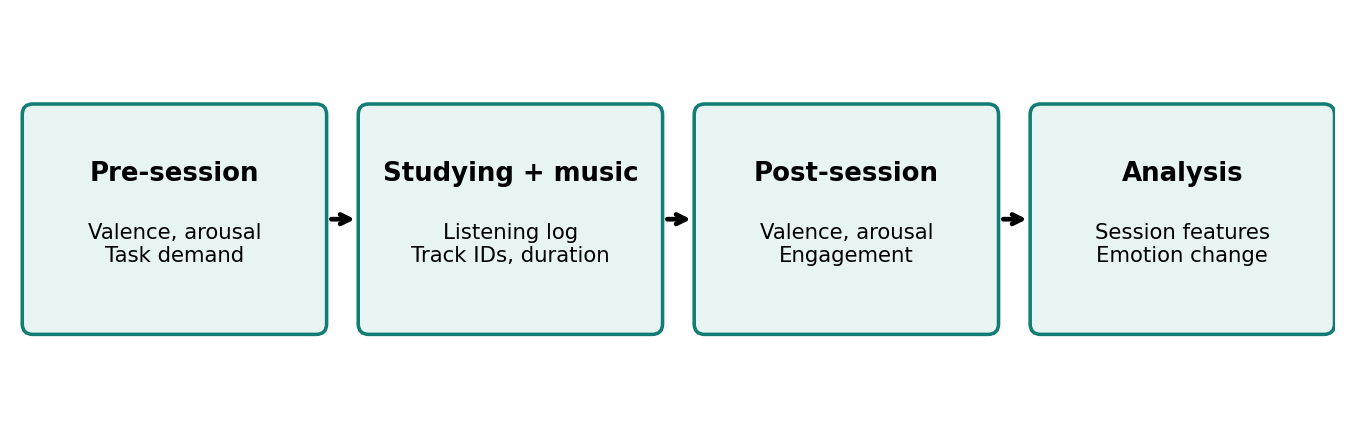

**Music metadata:**
- The music tracks were obtained from the [Jamendo](https://www.jamendo.com/) music library, which provides metadata such as genre and vocal/instrumental classification.
- We further enriched the music metadata with predicted **happiness (valence)** and **energy (arousal)** scores using Support Vector Regression (SVR) models trained on acoustic features (e.g., timbre, rhythm, and dynamics) extracted with [Librosa](https://librosa.org/), a Python library for audio and music analysis. These scores represent the *predicted emotional characteristics of the music*, rather than listeners' actual emotional responses.

**Goals for this demo:** Join surveys and music metadata (Connect **session surveys → listening exposure → music metadata**); compare pooled versus within-person correlations across session-level music features and learning outcome measures; explore the role of genre, lyric presence (vocal vs instrumental), and task context.

### Step 1: Mount Google Drive
Run the cell below to connect your Google Drive to this notebook. When prompted, authorize access to your Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


### Step 2: Set your dataset directory
Once your Drive is mounted, all of your files will be accessible under the path `/content/drive/MyDrive/`.

Find where the `sessions.csv`, `listening_history.csv`, and `music_metadata.csv` files are located in your Drive, and update the path `DATA_DIRECTORY` below (for example, `/content/drive/MyDrive/your_folder/`):

In [ ]:
from pathlib import Path
# Replace 'your_folder_path' with the actual path to your dataset folder in Drive
DATA_DIRECTORY=Path('/content/drive/MyDrive/ISMIR 2026 tutorial/Colab Notebooks/02 Naturalistic experiment data analysis/data')

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

sessions=pd.read_csv(DATA_DIRECTORY/'sessions.csv')
listening_history=pd.read_csv(DATA_DIRECTORY/'listening_history.csv')
music_metadata=pd.read_csv(DATA_DIRECTORY/'music_metadata.csv')
print(f'{sessions.participant_id.nunique()} learners, {len(sessions)} sessions, {len(listening_history)} listening events, {len(music_metadata)} tracks')

30 learners, 200 sessions, 2113 listening events, 180 tracks


### 1. Pre-processing and session-level aggregation

#### A. Integrate session info and listening data
`listening_history.csv` has multiple rows per session, while `sessions.csv` has one row per session. Join listening records to track metadata using `track_id`; aggregate to the session level; then join back to surveys using `session_id`.

> **Note:** For learning engagement measures from survey data, each three-item construct is computed as an arithmetic mean. The single `performance` item remains an integer (4 = no perceived music effect).

#### B. Extract session-level music features
- Calculate exposure-weighted musical happiness/energy.
- Calculate percentage of listening time with vocals (missing vocal labels are excluded).
- For genre, use the most-listened-to genre as a descriptive category to characterize the music played during a study session.


> **Exposure-weighted musical happiness/energy:** For a session with listening durations $t_i$ and predicted track happiness $h_i$, the exposure-weighted average is:
>
> $$
> H = \frac{\sum_i t_i h_i}{\sum_i t_i}
> $$
>
> A five-minute track should contribute more than one skipped after five seconds.
>
> **Percentage of listening time with vocals:** Vocal seconds divided by all seconds with a known vocal/instrumental label. Also report the proportion of total listening time whose label is known.
>
> **Interpretation:** These summaries describe what was heard, not necessarily what the learner preferred.
>
> **Discussion:** How might skipping behavior change an unweighted average?

In [ ]:
listening_with_metadata=listening_history.merge(music_metadata,on='track_id',validate='many_to_one')
sessions_grouped=listening_with_metadata.groupby('session_id')
session_music_features=sessions_grouped.apply(lambda genre_summary: pd.Series({
 'music_happiness':np.average(genre_summary.happiness,weights=genre_summary.listened_seconds),
 'music_energy':np.average(genre_summary.energy,weights=genre_summary.listened_seconds),
 'vocal_label_coverage':genre_summary.loc[genre_summary.vocal_status!='Unknown','listened_seconds'].sum()/genre_summary.listened_seconds.sum(),
 'vocal_share_known':(genre_summary.loc[genre_summary.vocal_status=='Vocal','listened_seconds'].sum()/genre_summary.loc[genre_summary.vocal_status!='Unknown','listened_seconds'].sum()) if (genre_summary.vocal_status!='Unknown').any() else np.nan,
 'dominant_genre':genre_summary.groupby('genre').listened_seconds.sum().idxmax()
}),include_groups=False)
analysis_data=sessions.merge(session_music_features,left_on='session_id',right_index=True,validate='one_to_one')
analysis_data['concentration']=analysis_data[['concentration_1','concentration_2','concentration_3']].mean(axis=1)
analysis_data['altered_sense_of_time']=analysis_data[['sense_of_time_1','sense_of_time_2','sense_of_time_3']].mean(axis=1)
analysis_data['perceived_music_effect']=analysis_data['performance']
analysis_data['delta_valence']=analysis_data.post_valence-analysis_data.pre_valence
analysis_data['delta_arousal']=analysis_data.post_arousal-analysis_data.pre_arousal
display(analysis_data.head(3))
print('Raw survey items and calculated scores (first 10 sessions):')
display(analysis_data[['session_id','concentration_1','concentration_2','concentration_3','concentration','sense_of_time_1','sense_of_time_2','sense_of_time_3','altered_sense_of_time','performance']].head(3).round(2))

,session_id,participant_id,task_type,mental_demand,temporal_demand,pre_valence,post_valence,pre_arousal,post_arousal,concentration_1,...,music_happiness,music_energy,vocal_label_coverage,vocal_share_known,dominant_genre,concentration,altered_sense_of_time,perceived_music_effect,delta_valence,delta_arousal
0,S001,P01,Other,6,4,-0.293,-0.025,-0.706,-0.531,3,...,0.635349,0.440566,0.697105,0.513312,Electronic,3.666667,4.000000,6,0.268,0.175
1,S002,P01,Other,3,2,-0.189,-0.312,0.181,0.174,6,...,0.682796,0.425590,1.000000,0.227242,Electronic,5.333333,3.000000,4,-0.123,-0.007
2,S003,P01,Other,2,4,-0.823,-0.652,0.409,0.696,5,...,0.468424,0.493788,0.812802,0.497771,Classical,4.333333,4.333333,3,0.171,0.287


Raw survey items and calculated scores (first 10 sessions):


,session_id,concentration_1,concentration_2,concentration_3,concentration,sense_of_time_1,sense_of_time_2,sense_of_time_3,altered_sense_of_time,performance
0,S001,3,4,4,3.67,3,6,3,4.00,6
1,S002,6,5,5,5.33,5,3,1,3.00,4
2,S003,5,4,4,4.33,4,4,5,4.33,3


### 2. Exploring the Music Library and Listening Behavior

Before examining how music relates to learners' emotions and studying experiences, let's first get to know the music they have access to and what they actually listen to.

**Two questions to start with:**
- What kinds of music are available in our music library? How do they differ in their emotional characteristics (happiness and energy)?
- What kinds of music do learners listen to most while studying? Are certain genres more common than others?

To explore these questions, we'll create two visualizations:

- **Music emotion map (left):** Each point represents a track in the music library, positioned according to its predicted happiness (valence) and energy (arousal). These describe the emotional characteristics of the music, rather than the emotions experienced by listeners.
- **Listening behavior by genre (right):** The proportion of total listening time spent on each genre across all studying sessions.

**Interpretation:** These visualizations provide an overview of the music collection and learners' listening behavior. However, listening to a genre more frequently does not necessarily mean preferring it. **Music availability and recommendation settings** may also influence what learners listen to.

**Discussion:** What if we counted the number of tracks listened to instead of total listening time? Would the distribution of genres look different?

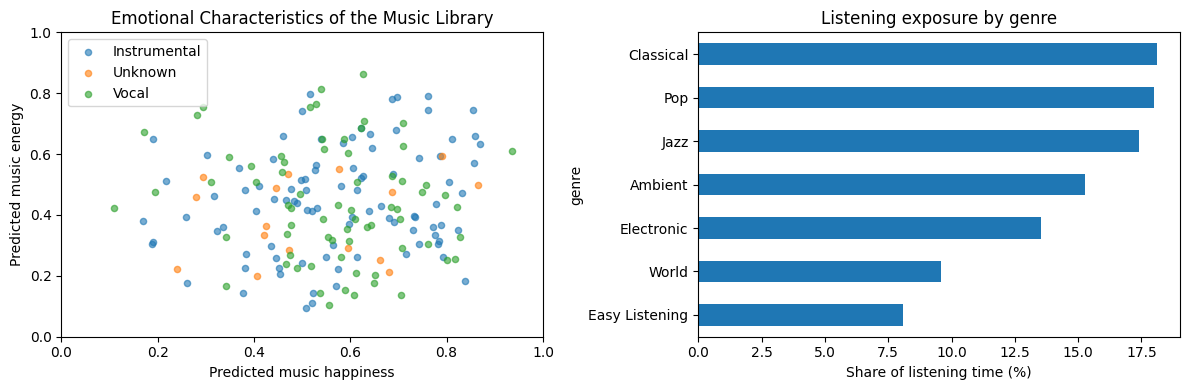

In [ ]:
figure,axes=plt.subplots(1,2,figsize=(12,4))
for label,group_data in music_metadata.groupby('vocal_status'):
 axes[0].scatter(group_data.happiness,group_data.energy,s=20,alpha=.6,label=label)
axes[0].legend();axes[0].set(xlabel='Predicted music happiness',ylabel='Predicted music energy',title='Emotional Characteristics of the Music Library',xlim=(0,1),ylim=(0,1))
(listening_with_metadata.groupby('genre').listened_seconds.sum()/listening_with_metadata.listened_seconds.sum()*100).sort_values().plot.barh(axes=axes[1])
axes[1].set(xlabel='Share of listening time (%)',title='Listening exposure by genre')
plt.tight_layout();plt.show()

### 3. Musical emotion versus experienced emotion
Track-level *predicted music emotion* is different from learner-level *experienced emotion*.

#### 🟨 Illustrative Analysis
Calculate experienced emotional change as post-session minus pre-session score. Positive valence change means the participant reported more pleasant affect at the end of the session; positive arousal change means higher activation.

Each point is a studying session. The fitted line is a descriptive pooled association and does not account for participant clustering.

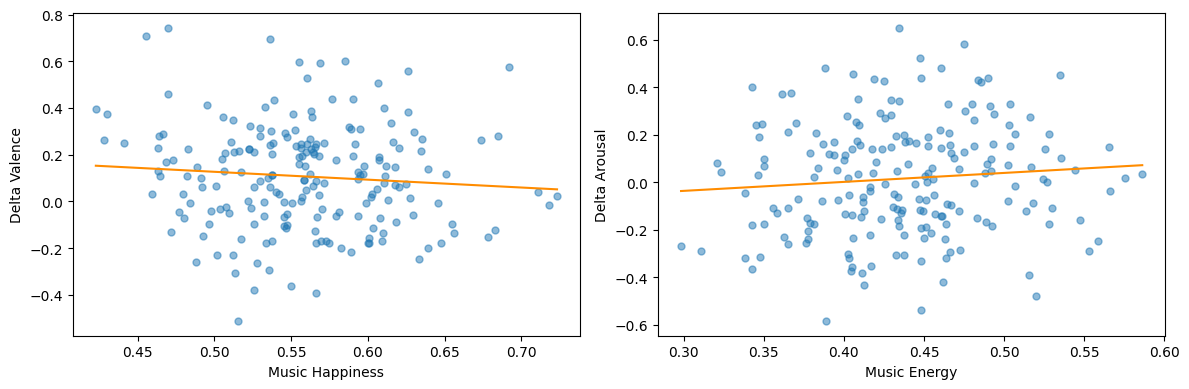

In [ ]:
figure,axes=plt.subplots(1,2,figsize=(12,4))
for axis,predictor_column,outcome_column in zip(axes,['music_happiness','music_energy'],['delta_valence','delta_arousal']):
 axis.scatter(analysis_data[predictor_column],analysis_data[outcome_column],alpha=.5,s=25)
 slope,intercept,*_=stats.linregress(analysis_data[predictor_column],analysis_data[outcome_column])
 grid=np.linspace(analysis_data[predictor_column].min(),analysis_data[predictor_column].max(),100)
 axis.plot(grid,intercept+slope*grid,color='darkorange')
 axis.set(xlabel=predictor_column.replace('_',' ').title(),ylabel=outcome_column.replace('_',' ').title())
plt.tight_layout();plt.show()


## 4. Repeated-Measures Correlation: Does Mood Improvement Relate to Perceived Learning Experience?

We have multiple studying sessions from each learner. **Are sessions with greater improvements in valence associated with more positive perceived effects of music on learning?**

To investigate this, we'll compare two approaches:

- **Pooled Pearson correlation:** Treats all studying sessions as independent observations, ignoring which learner they belong to.
- **Repeated-measures correlation (rmcorr):** Accounts for repeated observations from the same learner by estimating a common within-person association, allowing each learner to have a different intercept but sharing the same regression slope.

We'll visualize both approaches side by side:

- **Left:** One regression line fitted to all sessions, ignoring participant identity.
- **Right:** The same observations, with parallel regression lines representing the common within-person slope and participant-specific intercepts.

**Discussion:** Why might the pooled correlation differ from rmcorr? What could happen if some learners consistently report higher perceived learning effects than others?

In [ ]:

import statsmodels.formula.api as smf
import ipywidgets as widgets
from IPython.display import display

# Variables of interest
predictor = "delta_valence"
outcome = "perceived_music_effect"

# 1. Pooled Pearson correlation
pooled_r, pooled_p = stats.pearsonr(
    analysis_data[predictor], analysis_data[outcome]
)

# 2. Repeated-measures correlation
# Remove participant-specific means (within-person mean centering)
# i.e., For each studying session, subtract that participant's own average score
x_centered = analysis_data[predictor] - analysis_data.groupby(
    "participant_id"
)[predictor].transform("mean")

y_centered = analysis_data[outcome] - analysis_data.groupby(
    "participant_id"
)[outcome].transform("mean")

rmcorr_r = np.corrcoef(x_centered, y_centered)[0, 1]
degrees_of_freedom = (
    len(analysis_data) - analysis_data["participant_id"].nunique() - 1
)
rmcorr_p = 2 * stats.t.sf(
    abs(rmcorr_r * np.sqrt(
        degrees_of_freedom / (1 - rmcorr_r**2)
    )),
    degrees_of_freedom
)

# ANCOVA: common slope, participant-specific intercepts
model = smf.ols(
    f"{outcome} ~ {predictor} + C(participant_id)",
    data=analysis_data
).fit()

print(f"Pooled Pearson: r = {pooled_r:.3f}, p = {pooled_p:.3g}")
print(f"Repeated measures: r = {rmcorr_r:.3f}, p = {rmcorr_p:.3g}")

# 3. Prepare visualization
pooled_fit = stats.linregress(
    analysis_data[predictor], analysis_data[outcome]
)
x_range = np.linspace(
    analysis_data[predictor].min(),
    analysis_data[predictor].max(), 100
)

participants = sorted(analysis_data["participant_id"].unique())

# 4. Interactive visualization
@widgets.interact(
    selected_participant=widgets.Dropdown(
        options=participants,
        value=participants[0],
        description="Participant:"
    )
)
def plot_correlations(selected_participant):

    fig, axes = plt.subplots(
        1, 2, figsize=(12, 4.5),
        sharex=True, sharey=True
    )

    # LEFT: Pooled Pearson correlation (all sessions)
    axes[0].scatter(
        analysis_data[predictor],
        analysis_data[outcome],
        color="gray", alpha=0.35, s=25
    )
    axes[0].plot(
        x_range,
        pooled_fit.intercept + pooled_fit.slope * x_range,
        color="darkorange", linewidth=2
    )
    axes[0].set_title(f"Pooled Pearson (r = {pooled_r:.2f})")

    # RIGHT: Rmcorr with participant highlighting
    for participant, subset in analysis_data.groupby("participant_id"):

        highlighted = participant == selected_participant
        color = "royalblue" if highlighted else "lightgray"

        axes[1].scatter(
            subset[predictor], subset[outcome],
            color=color,
            alpha=0.9 if highlighted else 0.15,
            s=45 if highlighted else 18,
            zorder=3 if highlighted else 1
        )

        # Fitted line: shared slope, participant-specific intercept
        if highlighted:
            participant_x = np.linspace(
                subset[predictor].min(),
                subset[predictor].max(), 30
            )
            predictions = model.predict({
                predictor: participant_x,
                "participant_id": [participant] * len(participant_x)
            })

            axes[1].plot(
                participant_x, predictions,
                color="royalblue", linewidth=2.5,
                label=f"{participant} (common slope)"
            )

    axes[1].set_title(
        f"Repeated Measures (r = {rmcorr_r:.2f})"
    )
    axes[1].legend(loc="best")

    for ax in axes:
        ax.set_xlabel("Change in valence")
        ax.set_ylabel("Perceived music effect (1–7)")

    plt.tight_layout()
    plt.show()


Pooled Pearson: r = 0.230, p = 0.00105
Repeated measures: r = 0.264, p = 0.00048


interactive(children=(Dropdown(description='Participant:', options=('P01', 'P02', 'P03', 'P04', 'P05', 'P06', …


### 5. Does Task Demand Matter?

So far, we've examined how music characteristics and learners' emotional changes relate to their studying experiences. But **does the relationship between music and learning depend on what learners are doing?**

For example, music might help learners stay engaged during relatively easy tasks, but become distracting when tasks require greater mental effort.

#### Exploring the Role of Task Demand

In our survey, learners rated the **mental demand** of their studying tasks on a 7-point scale (1 = very low, 7 = very high).

To explore whether task demand matters, we'll divide studying sessions into two groups:
- **Lower mental demand:** Ratings of 1–4
- **Higher mental demand:** Ratings of 5–7

We'll then visualize the relationship between **predicted music happiness** and **self-reported concentration** in each group.

**Interpretation:** Compare the direction and strength of the relationships across the two groups. Do they appear similar, or does the association seem stronger under certain task conditions? Note that these are exploratory comparisons; differences in apparent slopes do not necessarily establish a statistically significant interaction.

**Discussion:** What are the advantages and disadvantages of dividing task demand into two groups? How might the analysis change if we treated mental demand as a continuous variable instead?


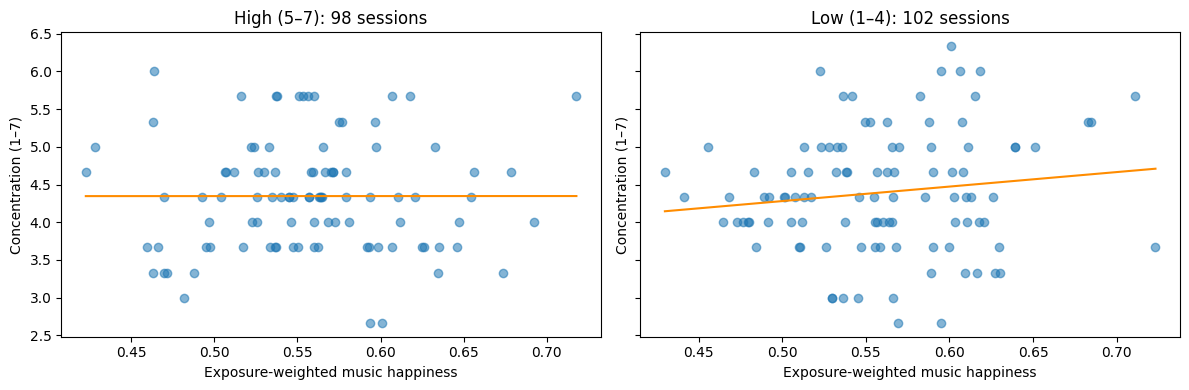

In [ ]:
analysis_data['demand_group']=np.where(analysis_data.mental_demand<=4,'Low (1–4)','High (5–7)')
figure,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for axis,(group,group_data) in zip(axes,analysis_data.groupby('demand_group')):
 axis.scatter(group_data.music_happiness,group_data.concentration,alpha=.55)
 slope,intercept,*_=stats.linregress(group_data.music_happiness,group_data.concentration)
 grid=np.linspace(group_data.music_happiness.min(),group_data.music_happiness.max(),100)
 axis.plot(grid,intercept+slope*grid,color='darkorange')
 axis.set(title=f'{group}: {len(group_data)} sessions',xlabel='Exposure-weighted music happiness',ylabel='Concentration (1–7)')
plt.tight_layout();plt.show()


## 6. Key Takeaways

What have we learned about analyzing music-listening experiences in naturalistic settings?

**1. Connecting music and user experience requires integrating multiple data sources.**
- Link **session surveys → listening histories → music metadata** to examine how music characteristics relate to learners' emotions and studying experiences.

**2. Naturalistic data are rich, but often messy.**
- Real-world listening involves skipping, pausing, and replaying tracks. Accurate analysis requires careful data cleaning, temporal alignment, and aggregation.
- For example, session-level music characteristics should reflect what was actually heard, rather than simply averaging all tracks in a playlist.

**3. Account for repeated observations and differences in user contexts.**
- Repeated observations from the same learner are not independent. Methods such as **repeated-measures correlation (rmcorr)** help identify common within-person associations.

### Try It Yourself

1. **Aggregation:** Replace listening-duration-weighted music happiness with an unweighted average. How much do the results change?
2. **Repeated measures:** Replace valence change with arousal change, and perceived enhance/distract effect of music with other engagement measures (e.g., altered sense of time). What does rmcorr reveal about this relationship?

**Reference:**

Li, F., & Hu, X. (2023). Background music for studying: A naturalistic experiment on music characteristics and user perception. IEEE Multimedia, 30(1).

Li, F., Hu, X., & Que, Y. (2020). Learning with background music: A field experiment. In Proceedings of the 10th International Conference on Learning Analytics & Knowledge (LAK ’20) (pp.224-229) ACM.

Li, F., Wang, Z., Ng, J. T. D. & Hu, X. (2021). Studying with learners’ own music: Preliminary findings on concentration and task load, In Proceedings of the 11th International Conference on Learning Analytics & Knowledge (LAK ’21) (pp.613-229) ACM.